# Notebook 23 — AESO overhead transmission costs and capacity–cost exploration

Explore whether AESO's component-level Tableau export supports an empirical cost
relationship for `ELC_TRANS`. Alberta observations are an **interim national proxy**,
not an estimated Canadian national average. No registry, model cost table, or database
is modified. This notebook uses pandas, numpy and matplotlib in the repository `.venv`.

The default run audits the export, builds **provisional component sums**, plots design
comparisons, and writes review tables. Capacity fitting runs only after documented cost
and engineering assumptions have been supplied. Missing information remains missing.

Source: [AESO transmission cost benchmarking](https://aeso.ca/grid/grid-planning/transmission-costs/).
User-supplied Tableau download: `1_Full Data_data.csv`; original download/publication
date is unknown. The export's latest observation date is computed below; it is not a
dashboard release date or a cost reference year. AESO's database includes estimates
and final costs; this export has no explicit cost-status field.

Acquisition decision: retain manually acquired sources under
`data_files/models/cost_models/transmission/`. No straightforward stable full-data
download was verified, so no Bronze stage or session-dependent scraper is added.
See that folder's README and `source_provenance.json` for the checks and refresh steps.
AESO calibrates line designs; Ontario packages and GSC examples are contextual checks,
not interchangeable training observations.


## 1. Source snapshot and explicit assumptions

The supplied CSV is read directly from `data_files/models/cost_models/transmission/`.
Its filename includes 2024, which is not assumed to be an observation or price year.
Recorded SHA-256: `6196e9c4af59ab92a1df7067a39b95b84dad39fbc6666f20e0c4306eddf77acf`.

Before fitting, confirm cost status, distance denominator conventions and component scope.
The dashboard evidence below establishes the price year and displayed unit.

User-provided AESO dashboard screenshot (reviewed 2026-10-27) explicitly states
**“CNST$: constant $ in 2016”** and labels the table **“Average ($/km)”**.
We therefore interpret the export's CNST$ component values as CAD 2016/km.
The screenshot also defines PPSS as nominal dollars in the proposal-year basis.
It does not resolve estimate/final status, route-km versus circuit-km conventions,
or the additivity/completeness of this particular export.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/geocanoe').is_dir())
SOURCE = ROOT / 'data_files/models/cost_models/transmission/AESO_Transmission_2024.csv'
OUT = ROOT / 'data_files/processed/transmission/aeso/notebook23'
OUT.mkdir(parents=True, exist_ok=True)
EXPECTED_SHA256 = '6196e9c4af59ab92a1df7067a39b95b84dad39fbc6666f20e0c4306eddf77acf'
assert SOURCE.is_file(), f'Place the supplied AESO export at {SOURCE}'
source_sha256 = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
assert source_sha256 == EXPECTED_SHA256, 'Source changed: review and update the recorded snapshot.'

# Persistent, reviewable assumptions; no automatic inflation or scope approval.
INPUTS = SOURCE.parent
COST_METADATA = json.loads((INPUTS / 'cost_assumptions.json').read_text(encoding='utf-8'))
PROVENANCE = json.loads((INPUTS / 'source_provenance.json').read_text(encoding='utf-8'))
assert source_sha256 == PROVENANCE['aeso']['sha256'], 'Review the source provenance after a refresh.'
POWER_FACTOR = 1.0  # Explicit MW conversion scenario, not a measured operating power factor.
CAPACITY_BASIS = 'summed circuit thermal rating; no N-1 or network constraint'
MIN_FIT_LINES = 10  # Exploratory safeguard, not proof of statistical adequacy.

raw = pd.read_csv(SOURCE)
print('Source SHA-256:', source_sha256)
display(raw.head())
display(pd.Series(COST_METADATA, name='Cost basis and remaining assumptions'))

Source SHA-256: 6196e9c4af59ab92a1df7067a39b95b84dad39fbc6666f20e0c4306eddf77acf
  Circuit  Year_Estimate       Line_Description  ... BDL  CCT           COST
0     s/c           2009    new_1-5km_s/c_1x266  ...   1  1.0    4385.964912
1     s/c           2008  new_10-50km_s/c_1x266  ...   1  1.0    5146.295135
2     s/c           2008  new_10-50km_s/c_1x266  ...   1  1.0    5567.355646
3     s/c           2008  new_10-50km_s/c_1x266  ...   1  1.0  170576.291486
4     s/c           2008  new_10-50km_s/c_1x477  ...   1  1.0   23630.007917

[5 rows x 20 columns]
unit                                                                   CAD/km
constant_dollar_year                                                     2016
distance_denominator                                                     None
cost_status                                                              None
scope_confirmed_additive                                                False
evidence                    User-provided AE

## 2. Audit observation counts, missingness, and repeated components

The independent unit is a line record, not an individual component row. Check that
design attributes are constant within each `LINE_ID`. Repeated component/category
keys may be revisions or separate work items; their identity cannot be resolved from
this export alone. Keep them for review and exclude their entire line from provisional
cost comparisons. Exact duplicates are flagged too, rather than silently removed.

In [2]:
required = {'LINE_ID', 'Year_Estimate', 'SRC_DATE', 'COMPONENT', 'COST', 'BASE',
            'KV', 'Voltage', 'Circuit', 'CDT', 'BDL', 'CCT', 'KM', 'ACTION', 'Type',
            'Labour&Material_PCM_ON_OT'}
assert required <= set(raw), required - set(raw)
data = raw.copy()
for col in ['Year_Estimate', 'COST', 'KV', 'BDL', 'CCT']:
    data[col] = pd.to_numeric(data[col], errors='coerce')
data['source_date'] = pd.to_datetime(data['SRC_DATE'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')
component_key = ['LINE_ID', 'Year_Estimate', 'COMPONENT', 'Labour&Material_PCM_ON_OT']
repeated = data.loc[data.duplicated(component_key, keep=False)].sort_values(component_key)
design_columns = ['Year_Estimate', 'BASE', 'KV', 'Voltage', 'Circuit', 'CDT', 'BDL',
                  'CCT', 'KM', 'ACTION', 'Type']
variation = data.groupby('LINE_ID')[design_columns].nunique(dropna=False)
inconsistent_ids = set(variation.index[variation.gt(1).any(axis=1)])
repeated_ids = set(repeated['LINE_ID'])
display(pd.Series({
    'component_rows': len(data), 'distinct_line_ids': data.LINE_ID.nunique(),
    'exact_duplicate_rows': int(raw.duplicated().sum()),
    'lines_with_repeated_component_keys': len(repeated_ids),
    'lines_with_inconsistent_design': len(inconsistent_ids),
    'latest_estimate_year': data.Year_Estimate.max(),
    'latest_source_date': data.source_date.max(),
}, name='Source audit'))
display(data.isna().sum().rename('missing_rows').to_frame())
display(repeated)
display(data.groupby(['Voltage', 'Circuit'], dropna=False).LINE_ID.nunique().rename('line_ids').to_frame())

component_rows                                       1241
distinct_line_ids                                     158
exact_duplicate_rows                                    1
lines_with_repeated_component_keys                      1
lines_with_inconsistent_design                          0
latest_estimate_year                                 2023
latest_source_date                    2023-10-30 00:00:00
Name: Source audit, dtype: object
                           missing_rows
Circuit                               0
Year_Estimate                         0
Line_Description                      0
LINE_ID                               0
BASE                                  0
COMPONENT                             0
Type                                  0
ACTION                                0
Bundle                                0
conductor                            12
KM                                    0
TYPE                                  7
Voltage                               0


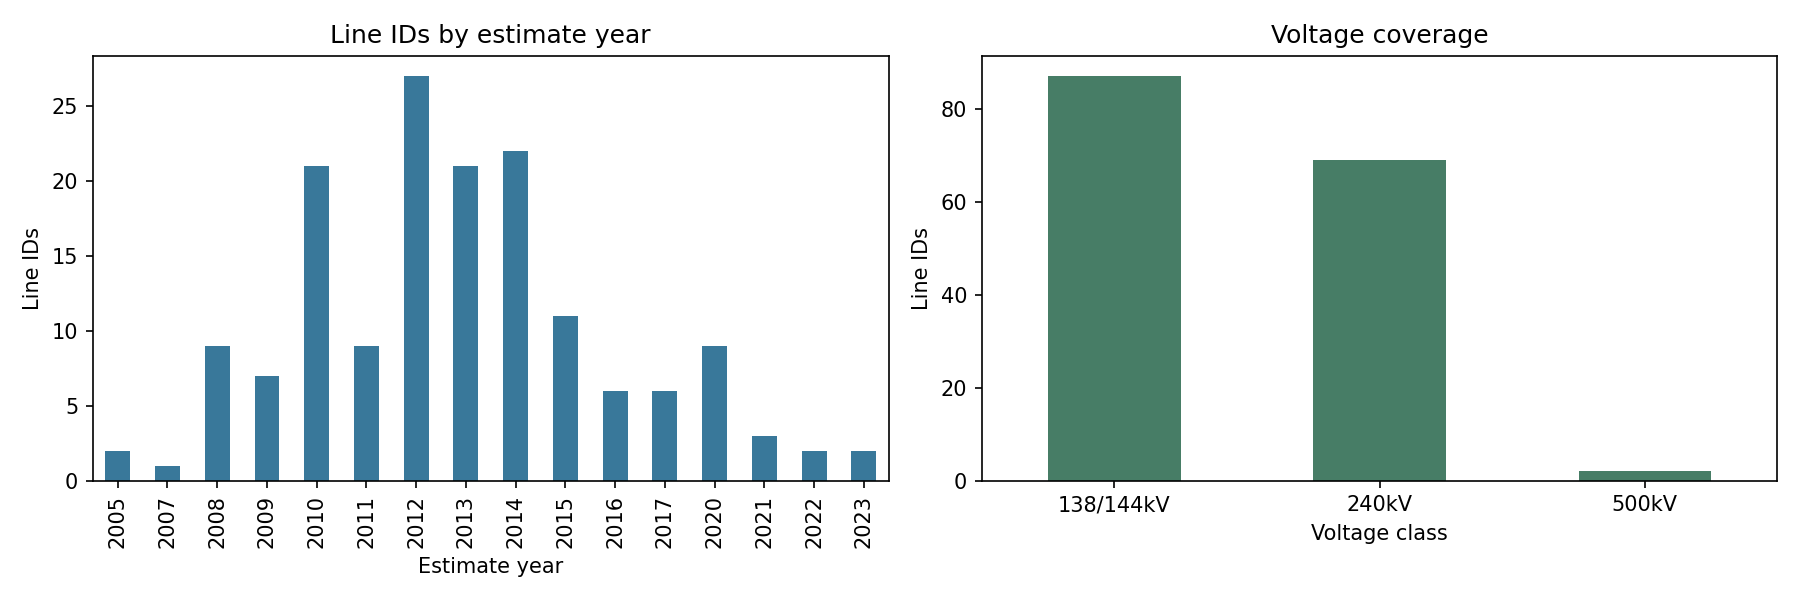

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data.groupby('Year_Estimate').LINE_ID.nunique().plot.bar(ax=axes[0], color='#39789a')
axes[0].set(title='Line IDs by estimate year', ylabel='Line IDs', xlabel='Estimate year')
data.groupby('Voltage').LINE_ID.nunique().plot.bar(ax=axes[1], color='#477d66', rot=0)
axes[1].set(title='Voltage coverage', ylabel='Line IDs', xlabel='Voltage class')
fig.tight_layout()
fig.savefig(OUT / 'source_coverage.png', dpi=150)
plt.show()

## 3. Component scope and provisional line-level aggregation

These are **sums of reported components**, not certified all-in project CAPEX.
Different component counts can mean different scope or reporting conventions.
`L.All_O` and other “other” categories require interpretation; they are not automatically
treated as totals or dropped. Examine the coverage matrix before confirming additivity.
Station costs, land acquisition, overheads, financing, contingency and taxes are not
assumed to be included merely because a line has many components.

`KM` is a length **bin**, not a numeric length: do not assign bin midpoints and divide
costs by them. The screenshot confirms $/km in constant 2016 dollars; no additional length division is applied.

The dashboard distinguishes the “Line” subtotal from contingency, escalation, owner,
PM & CM, others, pre-PPS, regulatory compliance and supply/install categories.
The supplied CSV contains line-related component categories only; do not interpret
their sum as total project cost. Do not sum the screenshot's category averages to
reconstruct a representative project: reporting populations and denominators may differ.


In [4]:
attributes = data.groupby('LINE_ID')[design_columns].first()
attributes['source_date'] = data.groupby('LINE_ID').source_date.max()
components = data.pivot_table(index='LINE_ID', columns='COMPONENT', values='COST', aggfunc='sum')
coverage = data.assign(present=1).pivot_table(
    index='LINE_ID', columns='COMPONENT', values='present', aggfunc='sum', fill_value=0)
lines = attributes.join(data.groupby('LINE_ID').agg(
    provisional_component_sum=('COST', 'sum'), component_rows=('COST', 'size'),
    component_types=('COMPONENT', 'nunique')))
lines['repeated_components'] = lines.index.isin(repeated_ids)
lines['inconsistent_design'] = lines.index.isin(inconsistent_ids)
bad_cost_ids = set(data.loc[data.COST.isna() | ~np.isfinite(data.COST) | (data.COST < 0), 'LINE_ID'])
lines['invalid_component_cost'] = lines.index.isin(bad_cost_ids)
lines['audit_eligible'] = ~(lines.repeated_components | lines.inconsistent_design | lines.invalid_component_cost)
lines['audit_eligible'] &= lines.provisional_component_sum.gt(0)
# Partial circuit additions are not comparable to full new line builds.
lines['complete_circuit_configuration'] = lines.Circuit.isin(['s/c', 'd/c', 't/c'])
lines['comparison_eligible'] = (lines.audit_eligible & lines.complete_circuit_configuration
                                & lines.ACTION.eq('new') & lines.Type.eq('ovh'))
comparisons = lines.loc[lines.comparison_eligible].copy()
display(coverage.head(15))
display(pd.DataFrame({'lines_reporting_component': coverage.gt(0).sum(),
                      'share_of_line_ids': coverage.gt(0).mean()}).sort_values('share_of_line_ids'))
display(lines.loc[~lines.comparison_eligible])
display(comparisons.head())
print('Provisional comparison lines:', len(comparisons), 'of', len(lines))

COMPONENT      Commissioning  Conductor  ...  ROW_Prep-Brush  Survey
LINE_ID                                  ...                        
L_10329974819              1          1  ...               1       1
L_10329974873              1          1  ...               1       1
L_10329974874              1          1  ...               1       1
L_10329974902              1          1  ...               1       1
L_10329974903              1          1  ...               1       1
L_10329974904              1          1  ...               1       1
L_10337611390              0          1  ...               1       1
L_10337611393              0          1  ...               1       1
L_10337611398              0          1  ...               1       1
L_10337611402              0          1  ...               1       1
L_10337611471              0          1  ...               1       1
L_10337611472              0          1  ...               1       1
L_10337611484              0      

## 4. Compare costs within electrical design classes

These plots describe the supplied export. They do not establish economies of scale:
terrain, scope, estimate quality and construction conditions remain uncontrolled.
The two 500 kV records cannot support a separate fitted curve.

                    n        median  ...       minimum       maximum
Voltage   Circuit                    ...                            
138/144kV d/c      24  1.296470e+06  ...  1.755261e+05  3.497510e+06
          s/c      60  5.875678e+05  ...  1.946199e+05  1.986914e+06
          t/c       1  2.345078e+06  ...  2.345078e+06  2.345078e+06
240kV     d/c      19  2.088604e+06  ...  8.896608e+05  4.097076e+06
          s/c      35  9.475023e+05  ...  9.539600e+04  3.279255e+06
          t/c       1  7.083607e+06  ...  7.083607e+06  7.083607e+06
500kV     d/c       2  1.279273e+07  ...  6.692778e+06  1.889268e+07

[7 rows x 6 columns]


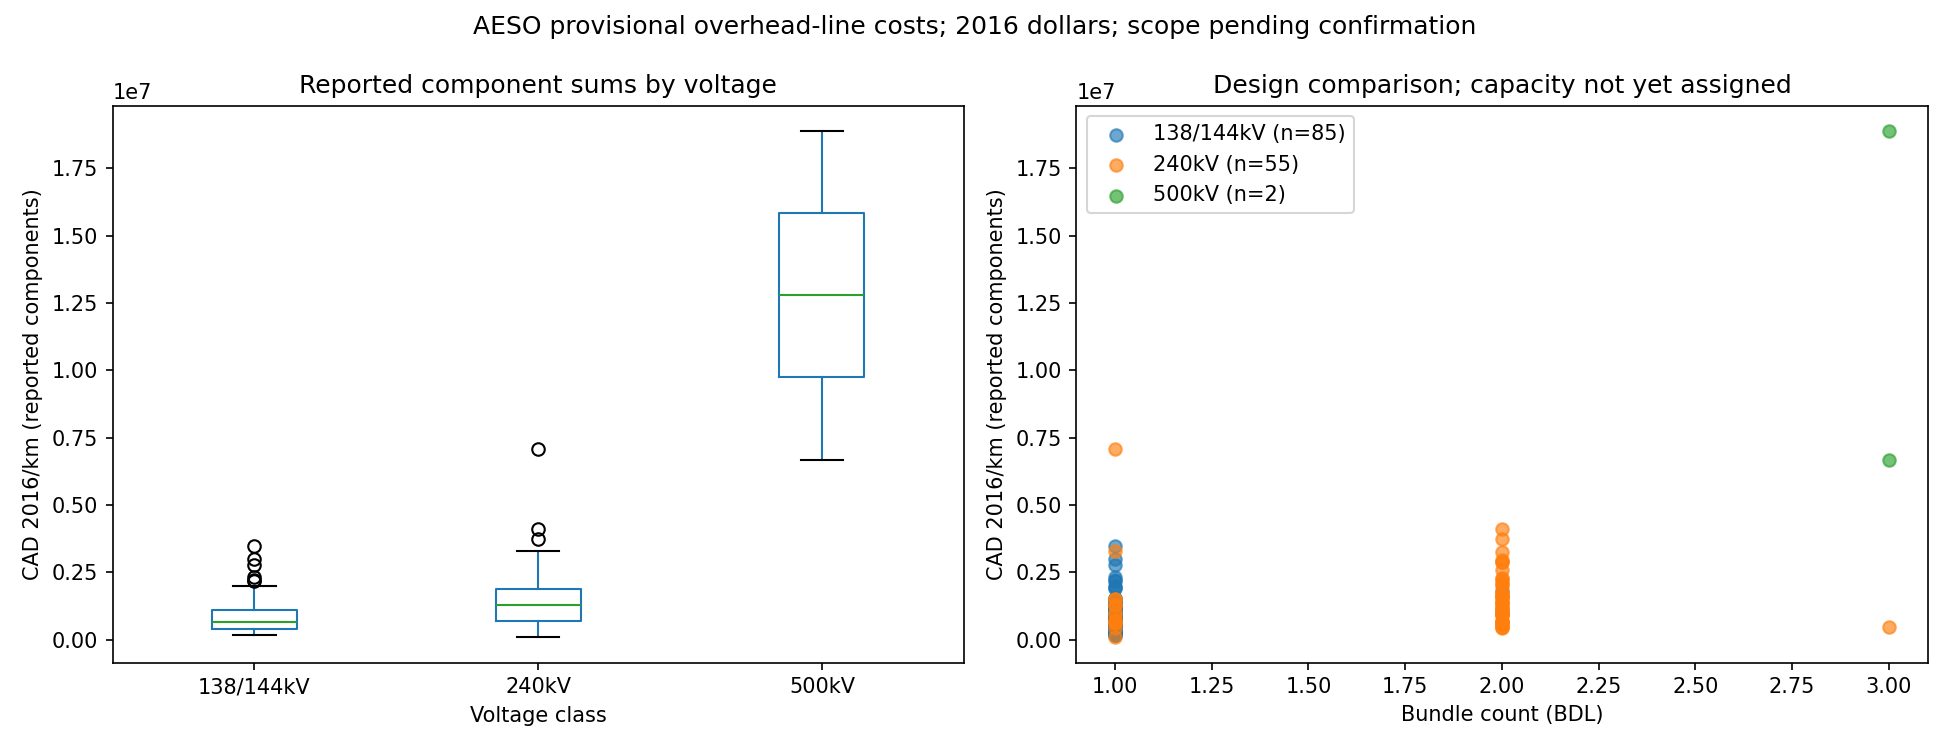

In [5]:
summary = comparisons.groupby(['Voltage', 'Circuit']).provisional_component_sum.agg(
    n='size', median='median', p25=lambda x: x.quantile(.25), p75=lambda x: x.quantile(.75),
    minimum='min', maximum='max')
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
comparisons.boxplot(column='provisional_component_sum', by='Voltage', ax=axes[0], grid=False)
axes[0].set(title='Reported component sums by voltage', xlabel='Voltage class', ylabel='CAD 2016/km (reported components)')
for voltage, group in comparisons.groupby('Voltage'):
    axes[1].scatter(group.BDL, group.provisional_component_sum, label=f'{voltage} (n={len(group)})', alpha=.65)
axes[1].set(xlabel='Bundle count (BDL)', ylabel='CAD 2016/km (reported components)', title='Design comparison; capacity not yet assigned')
axes[1].legend()
fig.suptitle('AESO provisional overhead-line costs; 2016 dollars; scope pending confirmation')
fig.tight_layout()
fig.savefig(OUT / 'provisional_design_costs.png', dpi=150)
plt.show()

## 5. Engineering lookup: design → thermal capacity

Supply a documented **single-subconductor ampacity** for each design, with the exact
conductor specification, temperature/weather assumptions and source. Conductor area
alone does not uniquely determine ampacity. Bundle effects must be reviewed; the simple
sum below is an explicit approximation, not a substitute for a line-rating study.

The external lookup is created only if absent; subsequent runs preserve edits. Fill
`ampacity_a_per_subconductor`, `rating_source`, `rating_conditions`, and mark
`approved_for_exploration=True` only for reviewed rows. Unmatched designs remain unrated.

For balanced three-phase AC, the exploratory design rating is:

`MVA = sqrt(3) × kV × ampacity_A × bundle_count × circuit_count / 1000`

`MW = MVA × power_factor`.

This is summed nominal thermal capacity, **not N-1 firm transfer capacity**. It excludes
voltage/stability limitations, terminal bottlenecks and network interactions. Do not
apply a blanket N-1 divisor. Neither this export nor voltage alone supplies actual MW.

In [6]:
design_keys = ['KV', 'CDT', 'BDL', 'CCT']
LOOKUP = INPUTS / 'design_ampacity_review.csv'
designs = comparisons[design_keys].drop_duplicates().sort_values(design_keys).reset_index(drop=True)
designs.insert(0, 'design_id', ['design_%03d' % i for i in range(1, len(designs) + 1)])
if not LOOKUP.exists():
    template = designs.copy()
    template['ampacity_a_per_subconductor'] = np.nan
    template['rating_source'] = ''
    template['rating_conditions'] = ''
    template['approved_for_exploration'] = False
    template.to_csv(LOOKUP, index=False)
ratings = pd.read_csv(LOOKUP)
assert not ratings.duplicated(design_keys).any(), 'Resolve duplicate electrical designs in the rating lookup.'
ratings['ampacity_a_per_subconductor'] = pd.to_numeric(ratings.ampacity_a_per_subconductor, errors='coerce')
approved = ratings.approved_for_exploration.astype(str).str.lower().eq('true')
valid_rating = (approved & ratings.ampacity_a_per_subconductor.gt(0)
                & np.isfinite(ratings.ampacity_a_per_subconductor)
                & ratings.rating_source.fillna('').str.strip().ne('')
                & ratings.rating_conditions.fillna('').str.strip().ne(''))
ratings['rating_ready'] = valid_rating
rated = comparisons.reset_index().merge(ratings, on=design_keys, how='left', validate='many_to_one')
assert 0 < POWER_FACTOR <= 1
rated['thermal_capacity_mva'] = (np.sqrt(3) * rated.KV * rated.ampacity_a_per_subconductor
                                * rated.BDL * rated.CCT / 1000)
valid_design = rated[design_keys].notna().all(axis=1) & rated[['KV', 'BDL', 'CCT']].gt(0).all(axis=1)
rated.loc[~(rated.rating_ready.fillna(False) & valid_design), 'thermal_capacity_mva'] = np.nan
rated['capacity_mw_scenario'] = rated.thermal_capacity_mva * POWER_FACTOR
display(rated[['LINE_ID', 'Voltage', 'Circuit', *[k for k in design_keys if k != 'KV'],
               'thermal_capacity_mva', 'capacity_mw_scenario', 'rating_source']])
print('Editable rating lookup:', LOOKUP)
print('Lines with reviewed thermal ratings:', rated.capacity_mw_scenario.notna().sum())
missing_designs = designs.merge(ratings[design_keys], on=design_keys, how='left', indicator=True)
missing_designs = missing_designs.loc[missing_designs['_merge'].eq('left_only')].drop(columns='_merge')
missing_designs.to_csv(OUT / 'new_designs_needing_ratings.csv', index=False)
if not missing_designs.empty:
    print('New designs absent from persistent lookup; add and review these without overwriting existing ratings:')
    display(missing_designs)


           LINE_ID    Voltage  ... capacity_mw_scenario rating_source
0    L_10329974819  138/144kV  ...                  NaN           NaN
1    L_10329974873  138/144kV  ...                  NaN           NaN
2    L_10329974874  138/144kV  ...                  NaN           NaN
3    L_10329974902  138/144kV  ...                  NaN           NaN
4    L_10329974903  138/144kV  ...                  NaN           NaN
..             ...        ...  ...                  ...           ...
137   L_9571682831      240kV  ...                  NaN           NaN
138   L_9789533111      240kV  ...                  NaN           NaN
139   L_9963495209      240kV  ...                  NaN           NaN
140   L_9963495218  138/144kV  ...                  NaN           NaN
141   L_9963495220  138/144kV  ...                  NaN           NaN

[142 rows x 9 columns]
Editable rating lookup: C:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\data_files\models\cost_models\transmission\d

## 6. Conditional capacity–cost fits and held-out-line validation

Fitting requires verified **CAD per route-km** in one common dollar year and a reviewed
additive component scope. If COST is a total, obtain actual route lengths first; binned
lengths are insufficient. Missing cost-status or scope evidence also leaves fitting off.

Compare a median baseline, a pooled power law, and a voltage/circuit-adjusted power law.
For `cost_per_km = a × capacity_MW ** b`, `b < 1` would imply declining unit capacity
cost **within the fitted population**, not proof of a causal economy of scale.
The adjusted model can be unidentifiable if capacity is determined entirely by design
class. Rank checks report this rather than silently returning arbitrary coefficients.

Validation leaves out one entire LINE_ID at a time; no components from that line enter
training. Independent projects may contain several LINE_IDs: project-group and regional
validation still require a project crosswalk. Geography is absent, so this is not ML
training for a terrain/land-cover surface. Do not extrapolate beyond observed designs.

`cost_assumptions.json` must specify `distance_denominator="route_km"` before fitting.
Do not mark this confirmed until the dashboard's circuit/length convention is verified.


In [7]:
cost_ready = (COST_METADATA['unit'] == 'CAD/km'
              and isinstance(COST_METADATA['constant_dollar_year'], int)
              and COST_METADATA.get('distance_denominator') == 'route_km'
              and bool(COST_METADATA['cost_status'])
              and COST_METADATA['scope_confirmed_additive'] is True
              and bool(COST_METADATA['evidence'].strip()))
fit_data = rated.loc[rated.capacity_mw_scenario.gt(0)].copy()
fit_results, cv_results = pd.DataFrame(), pd.DataFrame()

def matrix(frame, adjusted=False, columns=None):
    x = pd.DataFrame({'intercept': 1., 'log_capacity_mw': np.log(frame.capacity_mw_scenario)}, index=frame.index)
    if adjusted:
        classes = pd.get_dummies(frame[['Voltage', 'Circuit']].astype(str), drop_first=True, dtype=float)
        x = pd.concat([x, classes], axis=1)
    return x if columns is None else x.reindex(columns=columns, fill_value=0.)

def estimate(x, y):
    if len(y) <= x.shape[1] or np.linalg.matrix_rank(x) < x.shape[1]:
        raise ValueError('Too few observations or rank-deficient design matrix')
    return np.linalg.lstsq(x, np.log(y), rcond=None)[0]

if not cost_ready:
    print('Fits skipped: confirm route-km denominator, cost status and additive component scope in cost_assumptions.json; CAD 2016/km is documented.')
elif len(fit_data) < MIN_FIT_LINES or fit_data.capacity_mw_scenario.nunique() < 3:
    print('Fits skipped: need at least', MIN_FIT_LINES, 'reviewed lines and 3 distinct capacities.')
else:
    fit_data['cost_cad_per_km'] = fit_data.provisional_component_sum
    fit_data['cost_cad_per_mw_km'] = fit_data.cost_cad_per_km / fit_data.capacity_mw_scenario
    coefficients, predictions = [], []
    for model, adjusted in [('pooled_power_law', False), ('voltage_circuit_power_law', True)]:
        x = matrix(fit_data, adjusted)
        try:
            beta = estimate(x.to_numpy(), fit_data.cost_cad_per_km.to_numpy())
        except ValueError as exc:
            print(model, 'skipped:', exc)
            continue
        coefficients.extend({'model': model, 'term': term, 'coefficient_log_cost': value}
                            for term, value in zip(x.columns, beta))
        for idx, row in fit_data.iterrows():
            train = fit_data.drop(index=idx)
            # Singleton design classes cannot be validated as known classes.
            if adjusted and any(row[c] not in set(train[c]) for c in ['Voltage', 'Circuit']):
                continue
            try:
                b = estimate(x.drop(index=idx).to_numpy(), train.cost_cad_per_km.to_numpy())
            except ValueError:
                continue
            pred = float(np.exp(x.loc[idx].to_numpy() @ b))
            predictions.append({'model': model, 'LINE_ID': row.LINE_ID, 'actual': row.cost_cad_per_km,
                                'predicted': pred, 'median_baseline': train.cost_cad_per_km.median()})
    fit_results = pd.DataFrame(coefficients)
    cv_results = pd.DataFrame(predictions)
    display(fit_results)
    if not cv_results.empty:
        cv_results['absolute_error'] = abs(cv_results.actual - cv_results.predicted)
        cv_results['baseline_absolute_error'] = abs(cv_results.actual - cv_results.median_baseline)
        cv_results['absolute_percentage_error'] = cv_results.absolute_error / cv_results.actual
        display(cv_results.groupby('model').agg(n_held_out=('LINE_ID', 'size'),
            mae_cad_per_km=('absolute_error', 'mean'), median_ape=('absolute_percentage_error', 'median'),
            baseline_mae_cad_per_km=('baseline_absolute_error', 'mean')))
    fig, ax = plt.subplots(figsize=(8, 5))
    for voltage, g in fit_data.groupby('Voltage'):
        ax.scatter(g.capacity_mw_scenario, g.cost_cad_per_km, label=f'{voltage} (n={len(g)})', alpha=.7)
    pooled = fit_results.loc[fit_results.model.eq('pooled_power_law')] if not fit_results.empty else pd.DataFrame()
    if not pooled.empty:
        b = pooled.set_index('term').coefficient_log_cost
        grid = np.geomspace(fit_data.capacity_mw_scenario.min(), fit_data.capacity_mw_scenario.max(), 100)
        ax.plot(grid, np.exp(b['intercept']) * grid ** b['log_capacity_mw'], color='black', label='Pooled exploratory fit')
    ax.set(xscale='log', yscale='log', xlabel='Summed thermal MW scenario',
           ylabel=f"CAD {COST_METADATA['constant_dollar_year']} / route-km", title='Capacity–cost exploration')
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT / 'conditional_capacity_cost.png', dpi=150)
    plt.show()

Fits skipped: confirm route-km denominator, cost status and additive component scope in cost_assumptions.json; CAD 2016/km is documented.


## 7. Discrete transmission design options before selecting a curve

Summarize each electrical design as an option: observed line count, provisional
construction cost per km, interquartile spread, reviewed capacity and $/MW-km.
Blank capacity is an unresolved engineering input, not zero. No monotonic trend or
economy of scale is imposed. Options mix length bins and unobserved terrain, so their
spread is descriptive; it is not a prediction interval. Sparse designs remain visible.
Dollar basis and scope must still be reconciled before model integration. Keeping
options discrete is acceptable if a smooth power law does not predict held-out lines
better than the baseline or implies implausible interpolation between voltage classes.

In [8]:
option_keys = ['Voltage', 'Circuit', 'KV', 'CDT', 'BDL', 'CCT']
options = rated.groupby(option_keys, dropna=False).agg(
    n_lines=('LINE_ID', 'nunique'),
    component_cost_median_cad2016_per_km=('provisional_component_sum', 'median'),
    component_cost_p25_cad2016_per_km=('provisional_component_sum', lambda s: s.quantile(.25)),
    component_cost_p75_cad2016_per_km=('provisional_component_sum', lambda s: s.quantile(.75)),
    capacity_mw_scenario=('capacity_mw_scenario', 'median'),
    length_bins=('KM', lambda s: '|'.join(sorted(set(s)))),
    line_ids=('LINE_ID', lambda s: '|'.join(sorted(set(s)))),
).reset_index()
options['component_cost_cad2016_per_mw_km'] = (
    options.component_cost_median_cad2016_per_km / options.capacity_mw_scenario)
options['sparse_design'] = options.n_lines.lt(5)
options['scope'] = 'reported line components; completeness/additivity unresolved'
options['capacity_basis'] = CAPACITY_BASIS
display(options.drop(columns='line_ids'))
options.to_csv(OUT / 'discrete_design_options.csv', index=False)
print('Design options:', len(options), '| reviewed capacity options:', options.capacity_mw_scenario.notna().sum())

      Voltage  ...                                     capacity_basis
0   138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
1   138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
2   138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
3   138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
4   138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
5   138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
6   138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
7   138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
8   138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
9   138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
10  138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
11  138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
12  138/144kV  ...  summed circuit thermal rating; no N-1 or netwo...
13  138/144kV  ...  

## 8. Ontario and GSC context, retaining cost boundaries

`context_benchmarks.csv` contains manual transcriptions with locators and native price
years. GSC's two illustrative benchmarks derive from a three-project transmission
sample, mix voltage/material/terrain, and cannot identify a capacity curve or terrain
multiplier. Ontario estimates describe reinforcement packages, not isolated line CAPEX.
Neither source reports the comparable line thermal MW needed to join the AESO fit.

The table below preserves native values and optionally rebases them using the project's
existing audited economics policy. This policy currently covers 2000–2024; a 2025
Ontario value is left unconverted until an economic source covers 2025. Do not use a
2024 index for 2025. Dollar normalization does not reconcile scope.

The optional scenario below sums line options over route length plus **explicitly
supplied** terminal and other-project costs. Missing costs remain missing. A benchmark
package-minus-line residual is not automatically a station-cost estimate. It may also
contain contingency, scope, terrain and estimation differences. Ontario package
uncertainty (-50%/+100%) is not a fitted confidence interval.

In [9]:
import sys
sys.path.insert(0, str(ROOT / 'src'))
from geocanoe.costs.economics import conversion_basis

benchmarks = pd.read_csv(INPUTS / 'context_benchmarks.csv')
display(benchmarks)
conversion_rows = []
for _, row in benchmarks.iterrows():
    result = row.to_dict()
    result.update(normalized_cost=np.nan, normalized_currency=None, conversion_status='not attempted')
    try:
        basis = conversion_basis(row.currency, int(row.price_year))
        result.update(normalized_cost=row.cost_cad * basis['multiplier'],
                      normalized_currency=basis['target_currency'], conversion_status='converted; scope unchanged')
    except (ValueError, FileNotFoundError) as exc:
        result['conversion_status'] = str(exc)
    conversion_rows.append(result)
benchmark_review = pd.DataFrame(conversion_rows)
display(benchmark_review[['benchmark_id', 'price_year', 'cost_cad', 'cost_denominator',
                          'normalized_cost', 'normalized_currency', 'conversion_status']])
benchmark_review.to_csv(OUT / 'context_benchmark_review.csv', index=False)

def project_cost_scenario(line_cad_per_route_km, route_km, terminal_cad=None, other_cad=None):
    values = [line_cad_per_route_km, route_km, terminal_cad, other_cad]
    if any(v is None or not np.isfinite(v) for v in values):
        return np.nan
    if route_km <= 0 or any(v < 0 for v in [line_cad_per_route_km, terminal_cad, other_cad]):
        raise ValueError('Use positive length and nonnegative costs in one common price year.')
    return route_km * line_cad_per_route_km + terminal_cad + other_cad

print('No project scenario evaluated: select a reviewed design and supply terminal/other costs in the same price year.')

                benchmark_id  ... capacity_mw
0              gsc_25kv_flat  ...         NaN
1           gsc_120kv_rugged  ...         NaN
2      ontario_ottawa_phase1  ...         NaN
3  ontario_belleville_phase1  ...         NaN

[4 rows x 15 columns]
                benchmark_id  ...                                 conversion_status
0              gsc_25kv_flat  ...                        converted; scope unchanged
1           gsc_120kv_rugged  ...                        converted; scope unchanged
2      ontario_ottawa_phase1  ...  Missing source or target price year in GDP index
3  ontario_belleville_phase1  ...  Missing source or target price year in GDP index

[4 rows x 7 columns]
No project scenario evaluated: select a reviewed design and supply terminal/other costs in the same price year.


## 9. Save review tables and research decisions

Review outputs are local and ignored by Git. They retain the documented 2016-dollar basis;
they are not production cost layers. Missing components are not filled with zero for
scope assessment, even though provisional reported-component sums are computed.

Before selecting a national proxy:

- Retain CAD 2016/km as the documented basis; confirm estimate/final status, distance conventions and included overhead/ROW costs.
- Resolve repeated records and component-definition differences with AESO documentation.
- Source line/conductor thermal ratings; review full versus partial circuit construction.
- Compare within voltage/circuit/length classes and inspect influential expensive lines.
- Check sensitivity to ampacity/weather, cost coverage, exclusions and voltage population.
- Retain 500 kV as sparse benchmarks; seek additional projects before fitting that class.
- Obtain project IDs, route geometry, actual lengths and terrain for geographic calibration.
- Keep station costs separate when building route costs; convert MW to model units only
  after deciding whether nominal or firm transfer capacity is appropriate.

The current export supports design-cost exploration. It does not yet identify a unique
capacity curve or justify terrain multipliers, uncertainty intervals, or national weights.

Persistent source/assumption/rating inputs live in the models folder; generated outputs
can be deleted without losing reviewed inputs. Discrete options and contextual
benchmarks are exploratory and are not automatically inserted into ETLSegment tables.


In [10]:
raw.loc[raw.duplicated(keep=False)].to_csv(OUT / 'exact_duplicate_review.csv', index=False)
repeated.to_csv(OUT / 'repeated_component_review.csv', index=False)
lines.to_csv(OUT / 'provisional_line_costs.csv', index_label='LINE_ID')
coverage.to_csv(OUT / 'component_coverage.csv', index_label='LINE_ID')
summary.to_csv(OUT / 'design_cost_summary.csv')
rated.to_csv(OUT / 'line_capacity_review.csv', index=False)
if not fit_results.empty:
    fit_results.to_csv(OUT / 'exploratory_fit_coefficients.csv', index=False)
if not cv_results.empty:
    cv_results.to_csv(OUT / 'held_out_line_predictions.csv', index=False)
# The manifest, not leftover files from earlier runs, defines current valid outputs.
manifest = {
    'source_path': str(SOURCE.relative_to(ROOT)), 'source_sha256': source_sha256,
    'rows': len(raw), 'line_ids': int(data.LINE_ID.nunique()),
    'latest_estimate_year': int(data.Year_Estimate.max()),
    'latest_source_date': str(data.source_date.max()),
    'cost_metadata': COST_METADATA, 'capacity_basis': CAPACITY_BASIS,
    'power_factor_scenario': POWER_FACTOR, 'cost_ready': bool(cost_ready),
    'fit_completed': not fit_results.empty,
    'assumptions_sha256': hashlib.sha256((INPUTS / 'cost_assumptions.json').read_bytes()).hexdigest(),
    'provenance_sha256': hashlib.sha256((INPUTS / 'source_provenance.json').read_bytes()).hexdigest(),
    'benchmarks_sha256': hashlib.sha256((INPUTS / 'context_benchmarks.csv').read_bytes()).hexdigest(),
    'rating_lookup_sha256': hashlib.sha256(LOOKUP.read_bytes()).hexdigest(),
    'national_application': 'Alberta proxy; no national representativeness inferred',
}
(OUT / 'review_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('Review outputs:', OUT)
print('Capacity fit completed:', manifest['fit_completed'])

Review outputs: C:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\data_files\processed\transmission\aeso\notebook23
Capacity fit completed: False
